In [1]:
!nvidia-smi
!pip install -q transformers datasets peft accelerate scikit-learn matplotlib

Thu Oct 29 04:25:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
from datasets import load_dataset

dataset = load_dataset("zeroshot/twitter-financial-news-sentiment")
print(dataset)

for i in range(5):
    print(dataset["train"][i])

README.md:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

sent_train.csv:   0%|          | 0.00/859k [00:00<?, ?B/s]

sent_valid.csv:   0%|          | 0.00/217k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9543 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2388 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 9543
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2388
    })
})
{'text': '$BYND - JPMorgan reels in expectations on Beyond Meat https://t.co/bd0xbFGjkT', 'label': 0}
{'text': '$CCL $RCL - Nomura points to bookings weakness at Carnival and Royal Caribbean https://t.co/yGjpT2ReD3', 'label': 0}
{'text': '$CX - Cemex cut at Credit Suisse, J.P. Morgan on weak building outlook https://t.co/KN1g4AWFIb', 'label': 0}
{'text': '$ESS: BTIG Research cuts to Neutral https://t.co/MCyfTsXc2N', 'label': 0}
{'text': '$FNKO - Funko slides after Piper Jaffray PT cut https://t.co/z37IJmCQzB', 'label': 0}


In [4]:
from collections import Counter

names = {0: "negative", 1: "positive", 2: "neutral"}
counts = Counter(dataset["train"]["label"])

for k in sorted(counts):
    print(names[k], counts[k])

negative 1442
positive 1923
neutral 6178


In [5]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("FacebookAI/roberta-base")

text = "Tesla beats earnings, stock jumps 8%"
encoded = tokenizer(text)

print(encoded["input_ids"])
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"]))

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[0, 39971, 13410, 1107, 6, 388, 13855, 290, 207, 2]
['<s>', 'Tesla', 'Ġbeats', 'Ġearnings', ',', 'Ġstock', 'Ġjumps', 'Ġ8', '%', '</s>']


In [8]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [9]:
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from peft import LoraConfig, TaskType, get_peft_model

# Data
dataset = load_dataset("zeroshot/twitter-financial-news-sentiment")
splits = dataset["train"].train_test_split(test_size=0.1, seed=42)
train_data = splits["train"]
val_data = splits["test"]
test_data = dataset["validation"]

# Tokenize
tokenizer = AutoTokenizer.from_pretrained("FacebookAI/roberta-base")

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

train_data = train_data.map(tokenize, batched=True)
val_data = val_data.map(tokenize, batched=True)
test_data = test_data.map(tokenize, batched=True)

# Model + LoRA
id2label = {0: "negative", 1: "positive", 2: "neutral"}
label2id = {name: i for i, name in id2label.items()}

model = AutoModelForSequenceClassification.from_pretrained(
    "FacebookAI/roberta-base",
    num_labels=3,
    id2label=id2label,
    label2id=label2id,
)

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=16,
    lora_alpha=32,
    lora_dropout=0.1,
    target_modules=["query", "value"],
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 1,182,723 || all params: 125,830,662 || trainable%: 0.9399


In [10]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from transformers import DataCollatorWithPadding, Trainer, TrainingArguments

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro"),
    }

args = TrainingArguments(
    output_dir="outputs/lora_r16",
    num_train_epochs=4,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-4,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    fp16=True,
    logging_steps=50,
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_data,
    eval_dataset=val_data,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.411860,0.346542,0.875393,0.832992
2,0.352802,0.306536,0.889005,0.854992
3,0.308942,0.307549,0.874346,0.839537
4,0.285910,0.302252,0.880628,0.845401


TrainOutput(global_step=1076, training_loss=0.3657083905762456, metrics={'train_runtime': 84.08, 'train_samples_per_second': 408.563, 'train_steps_per_second': 12.797, 'total_flos': 978829256604816.0, 'train_loss': 0.3657083905762456, 'epoch': 4.0})

In [11]:
from sklearn.metrics import classification_report, confusion_matrix

out = trainer.predict(test_data)
y_true = out.label_ids
y_pred = np.argmax(out.predictions, axis=-1)
names = ["negative", "positive", "neutral"]

print(classification_report(y_true, y_pred, target_names=names, digits=3))
print(confusion_matrix(y_true, y_pred))

              precision    recall  f1-score   support

    negative      0.781     0.885     0.830       347
    positive      0.857     0.857     0.857       475
     neutral      0.940     0.913     0.926      1566

    accuracy                          0.897      2388
   macro avg      0.859     0.885     0.871      2388
weighted avg      0.900     0.897     0.898      2388

[[ 307    3   37]
 [  14  407   54]
 [  72   65 1429]]


In [12]:
import pandas as pd
from scipy.special import softmax

probs = softmax(out.predictions, axis=-1)
df = pd.DataFrame({
    "text": test_data["text"],
    "true": [names[i] for i in y_true],
    "pred": [names[i] for i in y_pred],
    "confidence": probs.max(axis=1),
})

wrong = df[df.true != df.pred].sort_values("confidence", ascending=False)
pd.set_option("display.max_colwidth", 120)
print(wrong.head(10))

                                                                                                                         text  \
981                                                                                                         Santa Claus rally   
231   NVIDIA : GPU-Powered Semi Simulation Snags Coveted Research Award #NVIDIA #Stock #MarketScreener… https://t.co/03Lwv...   
801   Bipartisan Group Of US Lawmakers Introduce Bill Providing $3B To Buy Oil To Fill Strategic Petroleum Reserve $SPY… h...   
972   Turkish banks refuse to lend to Istanbul, hey here's an idea: let's open it up to the European idiots who will buy… ...   
2373  $SUMRX: Gapping up/down: DOCU +10.5%, ULTA +9%, AOBC +7%, BIG +7%, CLDR +6.5% and CRWD +5% after earnings, TTD +5%.…...   
959                                                             Every Bubble Eventually Finds Its Pin https://t.co/E3LesbBMP1   
543    The bond market is looking 'overbought' even in the context of coronavirus fears, analysts

In [13]:
import torch

merged = model.merge_and_unload()
merged.eval()
merged.save_pretrained("outputs/lora_r16/model")
tokenizer.save_pretrained("outputs/lora_r16/model")

def predict(texts):
    enc = tokenizer(texts, truncation=True, max_length=128,
                    padding=True, return_tensors="pt").to(merged.device)
    with torch.no_grad():
        probs = torch.softmax(merged(**enc).logits, dim=-1)
    for t, p in zip(texts, probs):
        k = int(p.argmax())
        print(f"{names[k]:9} {p[k]:.0%}  {t}")

predict([
    "Tesla beats earnings, stock jumps 8%",
    "Bank reports record loan defaults, shares plunge",
    "Company to hold annual shareholder meeting on Tuesday",
    "Santa Claus rally",
])

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

positive  100%  Tesla beats earnings, stock jumps 8%
negative  100%  Bank reports record loan defaults, shares plunge
neutral   100%  Company to hold annual shareholder meeting on Tuesday
neutral   100%  Santa Claus rally


In [14]:
from scipy.special import softmax, log_softmax
import json

def get_logits(texts, batch_size=64):
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i+batch_size], truncation=True, max_length=128,
                        padding=True, return_tensors="pt").to(merged.device)
        with torch.no_grad():
            out.append(merged(**enc).logits.float().cpu().numpy())
    return np.concatenate(out)

val_logits = get_logits(val_data["text"])
test_logits = get_logits(test_data["text"])
val_labels = np.array(val_data["label"])
test_labels = np.array(test_data["label"])

best_T, best_nll = 1.0, 1e9
for T in np.linspace(0.5, 5.0, 91):
    lp = log_softmax(val_logits / T, axis=1)
    nll = -lp[np.arange(len(val_labels)), val_labels].mean()
    if nll < best_nll:
        best_T, best_nll = T, nll
print("best temperature:", round(best_T, 2))

def ece(probs, labels, bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    correct = (pred == labels)
    edges = np.linspace(0, 1, bins + 1)
    total = 0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return total

print("ECE before:", round(ece(softmax(test_logits, axis=1), test_labels), 4))
print("ECE after: ", round(ece(softmax(test_logits / best_T, axis=1), test_labels), 4))
print("accuracy (unchanged):", round((test_logits.argmax(1) == test_labels).mean(), 4))

json.dump({"temperature": float(best_T)}, open("outputs/lora_r16/model/calibration.json", "w"))

best temperature: 1.15
ECE before: 0.0204
ECE after:  0.0121
accuracy (unchanged): 0.8974


In [15]:
fb_tok = AutoTokenizer.from_pretrained("ProsusAI/finbert")
fb = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert").to(merged.device).eval()
print(fb.config.id2label)

name_to_id = {v.lower(): k for k, v in fb.config.id2label.items()}
order = [name_to_id[n] for n in names]

fb_logits = []
texts = test_data["text"]
for i in range(0, len(texts), 64):
    enc = fb_tok(texts[i:i+64], truncation=True, max_length=128,
                 padding=True, return_tensors="pt").to(fb.device)
    with torch.no_grad():
        fb_logits.append(fb(**enc).logits[:, order].float().cpu().numpy())
fb_pred = np.concatenate(fb_logits).argmax(1)

ours_pred = test_logits.argmax(1)
print("FinBERT  accuracy:", round(accuracy_score(test_labels, fb_pred), 4),
      " macro F1:", round(f1_score(test_labels, fb_pred, average="macro"), 4))
print("Ours     accuracy:", round(accuracy_score(test_labels, ours_pred), 4),
      " macro F1:", round(f1_score(test_labels, ours_pred, average="macro"), 4))

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{0: 'positive', 1: 'negative', 2: 'neutral'}
FinBERT  accuracy: 0.7253  macro F1: 0.6682
Ours     accuracy: 0.8974  macro F1: 0.8709


latency p50 15.7 ms, p95 18.3 ms


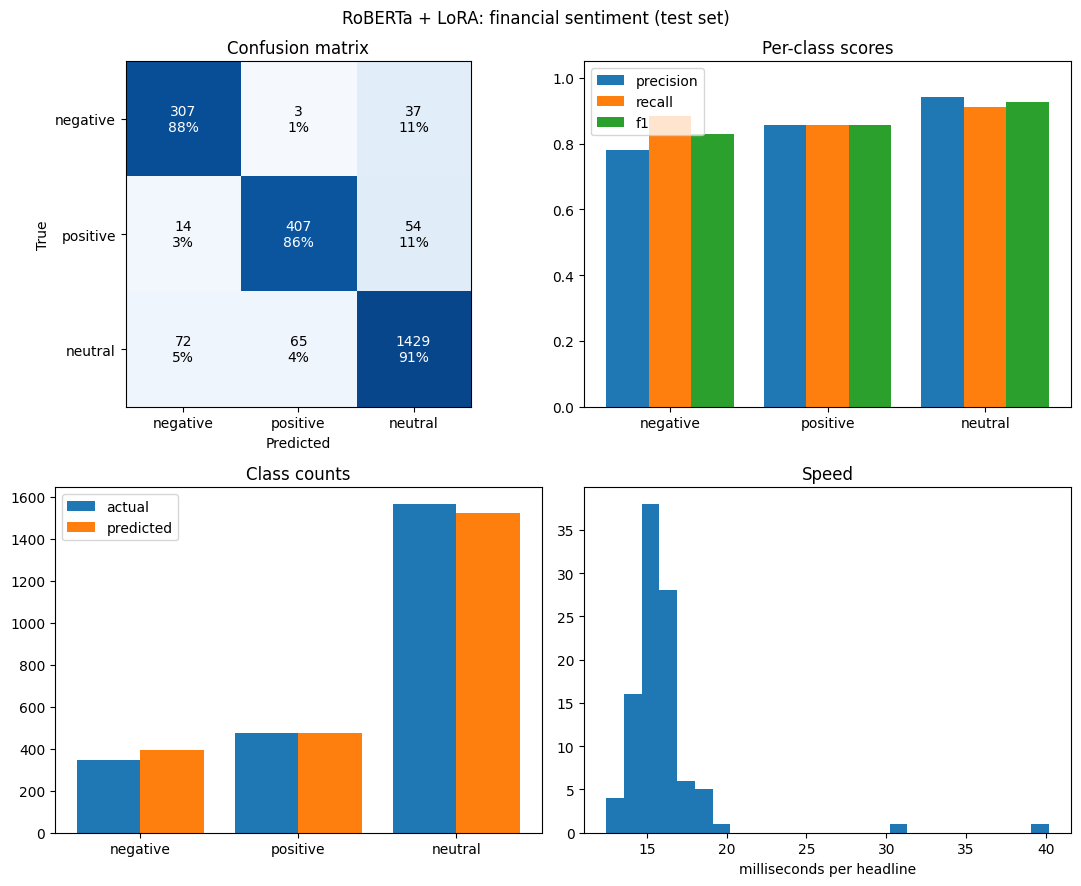

In [16]:
import matplotlib.pyplot as plt
import time, os
from sklearn.metrics import precision_recall_fscore_support

os.makedirs("reports", exist_ok=True)
cm = confusion_matrix(test_labels, ours_pred)
prec, rec, f1s, _ = precision_recall_fscore_support(test_labels, ours_pred)

# speed: time one headline at a time
lat = []
for t in test_data["text"][:105]:
    enc = tokenizer(t, truncation=True, max_length=128, return_tensors="pt").to(merged.device)
    torch.cuda.synchronize(); t0 = time.perf_counter()
    with torch.no_grad():
        merged(**enc)
    torch.cuda.synchronize(); lat.append((time.perf_counter() - t0) * 1000)
lat = np.array(lat[5:])  # ignore the first 5 warm-up runs
print(f"latency p50 {np.percentile(lat, 50):.1f} ms, p95 {np.percentile(lat, 95):.1f} ms")

fig, ax = plt.subplots(2, 2, figsize=(11, 9))

norm = cm / cm.sum(1, keepdims=True)
ax[0, 0].imshow(norm, cmap="Blues", vmin=0, vmax=1)
ax[0, 0].set_xticks(range(3), names); ax[0, 0].set_yticks(range(3), names)
ax[0, 0].set_xlabel("Predicted"); ax[0, 0].set_ylabel("True")
ax[0, 0].set_title("Confusion matrix")
for i in range(3):
    for j in range(3):
        ax[0, 0].text(j, i, f"{cm[i, j]}\n{norm[i, j]:.0%}", ha="center", va="center",
                      color="white" if norm[i, j] > 0.5 else "black")

x = np.arange(3)
ax[0, 1].bar(x - 0.27, prec, 0.27, label="precision")
ax[0, 1].bar(x, rec, 0.27, label="recall")
ax[0, 1].bar(x + 0.27, f1s, 0.27, label="f1")
ax[0, 1].set_xticks(x, names); ax[0, 1].set_ylim(0, 1.05)
ax[0, 1].legend(); ax[0, 1].set_title("Per-class scores")

ax[1, 0].bar(x - 0.2, np.bincount(test_labels), 0.4, label="actual")
ax[1, 0].bar(x + 0.2, np.bincount(ours_pred), 0.4, label="predicted")
ax[1, 0].set_xticks(x, names); ax[1, 0].legend(); ax[1, 0].set_title("Class counts")

ax[1, 1].hist(lat, bins=25)
ax[1, 1].set_xlabel("milliseconds per headline"); ax[1, 1].set_title("Speed")

fig.suptitle("RoBERTa + LoRA: financial sentiment (test set)")
fig.tight_layout()
fig.savefig("reports/lora_r16_eval.png", dpi=150)
plt.show()

In [17]:
!zip -rq results.zip reports outputs/lora_r16/model
from google.colab import files
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
!pip install -q fastapi uvicorn httpx

In [20]:
%%writefile api.py
import json, os
import torch
from fastapi import FastAPI
from pydantic import BaseModel, Field
from transformers import AutoModelForSequenceClassification, AutoTokenizer

MODEL_PATH = os.getenv("MODEL_PATH", "outputs/lora_r16/model")

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH).eval()
id2label = {int(k): v for k, v in model.config.id2label.items()}

cal_file = os.path.join(MODEL_PATH, "calibration.json")
T = json.load(open(cal_file))["temperature"] if os.path.exists(cal_file) else 1.0

app = FastAPI(title="Financial Sentiment API")


class Headline(BaseModel):
    text: str = Field(..., min_length=1, max_length=1000)


@app.get("/health")
def health():
    return {"status": "ok"}


@app.post("/predict")
def predict(body: Headline):
    enc = tokenizer(body.text, truncation=True, max_length=128, return_tensors="pt")
    with torch.no_grad():
        probs = torch.softmax(model(**enc).logits / T, dim=-1)[0]
    k = int(probs.argmax())
    return {
        "label": id2label[k],
        "confidence": round(float(probs[k]), 4),
        "scores": {id2label[i]: round(float(p), 4) for i, p in enumerate(probs)},
    }

Writing api.py


In [21]:
from fastapi.testclient import TestClient
import api

client = TestClient(api.app)
print(client.get("/health").json())
print(client.post("/predict", json={"text": "Bank reports record loan defaults, shares plunge"}).json())
print(client.post("/predict", json={"text": ""}).status_code)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{'status': 'ok'}
{'label': 'negative', 'confidence': 0.9902, 'scores': {'negative': 0.9902, 'positive': 0.002, 'neutral': 0.0077}}
422


In [22]:
!pip install -q gradio

In [23]:
%%writefile app.py
import torch
import gradio as gr
from api import tokenizer, model, id2label, T


def analyze(text):
    if not text.strip():
        return {}
    enc = tokenizer(text, truncation=True, max_length=128, return_tensors="pt")
    with torch.no_grad():
        probs = torch.softmax(model(**enc).logits / T, dim=-1)[0]
    return {id2label[i]: float(p) for i, p in enumerate(probs)}


demo = gr.Interface(
    fn=analyze,
    inputs=gr.Textbox(lines=3, label="Financial headline"),
    outputs=gr.Label(num_top_classes=3, label="Sentiment"),
    title="Financial Sentiment Intelligence",
    description="RoBERTa fine-tuned with LoRA on financial news tweets. Type a headline.",
    examples=[
        ["Tesla beats earnings, stock jumps 8%"],
        ["Bank reports record loan defaults, shares plunge"],
        ["Company to hold annual shareholder meeting on Tuesday"],
        ["Santa Claus rally"],
    ],
)

if __name__ == "__main__":
    demo.launch()

Writing app.py


In [24]:
from app import demo
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9f61db6f2acd63ba3b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [25]:
from google.colab import files
files.download("api.py")
files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>